In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Paramètres
vocab_size = 20000
maxlen = 200

# Charger IMDb dataset
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

# Padding des séquences
x_train = pad_sequences(x_train, maxlen=maxlen, padding='post')
x_test = pad_sequences(x_test, maxlen=maxlen, padding='post')

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)


x_train shape: (25000, 200)
x_test shape: (25000, 200)


In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128),  # plus besoin de input_length
    Bidirectional(LSTM(128)),
    Dense(1, activation='sigmoid')
])

# On précise la forme de l'input pour construire le modèle
model.build(input_shape=(None, maxlen))

# Compilation
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# Maintenant summary fonctionnera correctement
model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 200, 128)            │       2,560,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 256)                 │         263,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,823,425 (10.77 MB)

 Trainable params: 2,823,425 (10.77 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 189s 577ms/step - accuracy: 0.7305 - loss: 0.5167 - val_accuracy: 0.8574 - val_loss: 0.3559
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 178s 569ms/step - accuracy: 0.8929 - loss: 0.2765 - val_accuracy: 0.8702 - val_loss: 0.3216
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 186s 593ms/step - accuracy: 0.9365 - loss: 0.1756 - val_accuracy: 0.8738 - val_loss: 0.3232
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 177s 566ms/step - accuracy: 0.9586 - loss: 0.1213 - val_accuracy: 0.8672 - val_loss: 0.4071
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 177s 567ms/step - accuracy: 0.9740 - loss: 0.0793 - val_accuracy: 0.8588 - val_loss: 0.3885


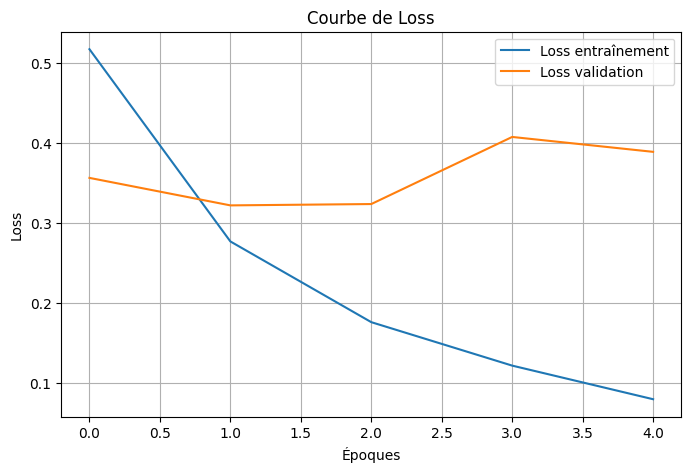

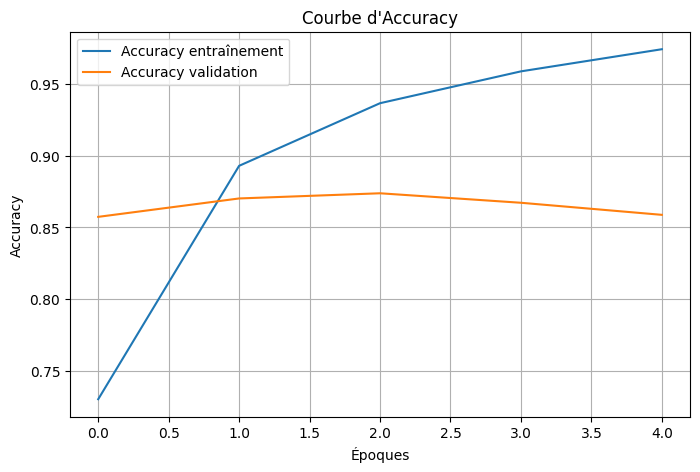

In [5]:
import matplotlib.pyplot as plt

# ---- Courbe Loss ----
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Loss entraînement')
plt.plot(history.history['val_loss'], label='Loss validation')
plt.title("Courbe de Loss")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# ---- Courbe Accuracy ----
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Accuracy entraînement')
plt.plot(history.history['val_accuracy'], label='Accuracy validation')
plt.title("Courbe d'Accuracy")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [6]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Précision sur le jeu de test :", test_acc)


782/782 ━━━━━━━━━━━━━━━━━━━━ 79s 101ms/step - accuracy: 0.8443 - loss: 0.4223
Précision sur le jeu de test : 0.8442800045013428


In [27]:
!pip install transformers torch


In [32]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import pipeline


In [12]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import pipeline

model_name = "nlptown/bert-base-multilingual-uncased-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

sentiment_pipeline = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

texts = [
    "I loved this movie!",
    "Ce produit est horrible.",
    "الفيلم كان رائعاً",
    "The food was bad.",
    "un trés bon film pour dormir",
   
]

# Fonction pour mapper les étoiles en Positif / Négatif
def map_star_to_sentiment(star_label):
    if "1" in star_label or "2" in star_label:
        return "Négatif"
    elif "4" in star_label or "5" in star_label:
        return "Positif"
    else:
        return "Neutre"

for text in texts:
    result = sentiment_pipeline(text)[0]
    sentiment = map_star_to_sentiment(result['label'])
    print(f"Avis : {text}")
    
    print(f"Sentiment prédit : {sentiment} (score : {result['score']:.2f})\n")


Device set to use cpu


Avis : I loved this movie!
Sentiment prédit : Positif (score : 0.84)

Avis : Ce produit est horrible.
Sentiment prédit : Négatif (score : 0.94)

Avis : الفيلم كان رائعاً
Sentiment prédit : Positif (score : 0.37)

Avis : The food was bad.
Sentiment prédit : Négatif (score : 0.43)

Avis : un trés bon film pour dormir
Sentiment prédit : Positif (score : 0.47)

